Unlabelled data: (6000, 784)
Labelled data: (1000, 784)
Testing data: (1000, 784)

Training First RBM: 784 -> 500
Epoch 1/3 Reconstruction Error: 0.0731
Epoch 2/3 Reconstruction Error: 0.0656
Epoch 3/3 Reconstruction Error: 0.0641
First RBM completed.
First layer feature shape: (6000, 500)

Training Second RBM: 500 -> 250
Epoch 1/3 Reconstruction Error: 0.0055
Epoch 2/3 Reconstruction Error: 0.0050
Epoch 3/3 Reconstruction Error: 0.0049


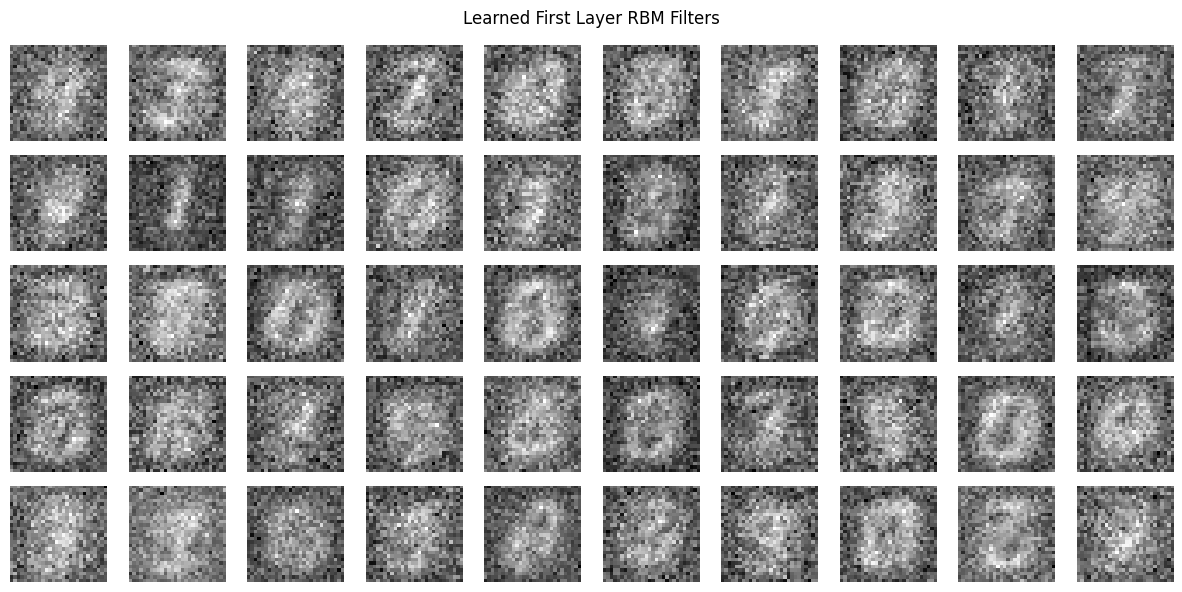

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


ValueError: Layer dense_103 weight shape (784, 500) is not compatible with provided weight shape (500, 784).

In [31]:
# EXPERIMENT 27: DEEP BELIEF NETWORK REPRESENTATION LEARNING

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import time

from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.utils import to_categorical
from sklearn.decomposition import PCA

np.random.seed(42)
tf.random.set_seed(42)

# --------------------------------------------------
# 1. LOAD MNIST DATA
# --------------------------------------------------

(X_train, y_train), (X_test, y_test) = mnist.load_data()

# Normalize and flatten
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

X_train = X_train.reshape(-1, 784)
X_test = X_test.reshape(-1, 784)

# Use 6000 data samples for unsupervised pretraining
X_unlabelled = X_train[:6000]

# Only 1000 labelled samples for supervised fine-tuning
X_labelled = X_train[:1000]
y_labelled = y_train[:1000]

X_test_small = X_test[:1000]
y_test_small = y_test[:1000]

y_labelled_cat = to_categorical(y_labelled, 10)
y_test_cat = to_categorical(y_test_small, 10)

print("Unlabelled data:", X_unlabelled.shape)
print("Labelled data:", X_labelled.shape)
print("Testing data:", X_test_small.shape)

# --------------------------------------------------
# 2. RBM IMPLEMENTATION
# --------------------------------------------------

def sigmoid(x):
    x = np.clip(x, -50, 50)
    return 1 / (1 + np.exp(-x))


class RBM:

    def __init__(self, n_visible, n_hidden, learning_rate=0.01):

        self.n_visible = n_visible
        self.n_hidden = n_hidden
        self.lr = learning_rate

        self.W = np.random.normal(
            0, 0.01, (n_visible, n_hidden)
        ).astype(np.float32)

        self.v_bias = np.zeros(n_visible, dtype=np.float32)
        self.h_bias = np.zeros(n_hidden, dtype=np.float32)

    def hidden_prob(self, v):
        return sigmoid(v @ self.W + self.h_bias)

    def visible_prob(self, h):
        return sigmoid(h @ self.W.T + self.v_bias)

    def sample(self, prob):
        return (np.random.rand(*prob.shape) < prob).astype(np.float32)

    def train(self, data, epochs=3, batch_size=100):

        errors = []

        for epoch in range(epochs):

            np.random.shuffle(data)

            epoch_error = 0
            batches = 0

            for start in range(0, len(data), batch_size):

                batch = data[start:start + batch_size]

                if len(batch) != batch_size:
                    continue

                # Positive phase
                h0_prob = self.hidden_prob(batch)
                h0_sample = self.sample(h0_prob)

                # Negative phase: CD-1
                v1_prob = self.visible_prob(h0_sample)
                v1_sample = self.sample(v1_prob)

                h1_prob = self.hidden_prob(v1_sample)

                # Weight updates
                self.W += self.lr * (
                    batch.T @ h0_prob -
                    v1_sample.T @ h1_prob
                ) / batch_size

                self.v_bias += self.lr * np.mean(
                    batch - v1_sample, axis=0
                )

                self.h_bias += self.lr * np.mean(
                    h0_prob - h1_prob, axis=0
                )

                # Reconstruction error
                reconstruction = self.visible_prob(
                    self.hidden_prob(batch)
                )

                error = np.mean((batch - reconstruction) ** 2)

                epoch_error += error
                batches += 1

            avg_error = epoch_error / max(batches, 1)
            errors.append(avg_error)

            print(
                f"Epoch {epoch + 1}/{epochs} "
                f"Reconstruction Error: {avg_error:.4f}"
            )

        return errors


# --------------------------------------------------
# 3. TRAIN FIRST RBM (784 -> 500)
# --------------------------------------------------

print("\nTraining First RBM: 784 -> 500")

rbm1 = RBM(784, 500)

start_time = time.time()

errors1 = rbm1.train(
    X_unlabelled.copy(),
    epochs=3
)

time1 = time.time() - start_time

# Extract first layer features
features1 = rbm1.hidden_prob(X_unlabelled)

print("First RBM completed.")
print("First layer feature shape:", features1.shape)

# --------------------------------------------------
# 4. TRAIN SECOND RBM (500 -> 250)
# --------------------------------------------------

print("\nTraining Second RBM: 500 -> 250")

rbm2 = RBM(500, 250)

start_time = time.time()

errors2 = rbm2.train(
    features1.copy(),
    epochs=3
)

time2 = time.time() - start_time

# --------------------------------------------------
# 5. VISUALIZE FIRST RBM WEIGHTS
# --------------------------------------------------

plt.figure(figsize=(12, 6))

for i in range(50):

    plt.subplot(5, 10, i + 1)

    weight_image = rbm1.W[:, i].reshape(28, 28)

    plt.imshow(weight_image, cmap="gray")
    plt.axis("off")

plt.suptitle("Learned First Layer RBM Filters")
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 6. CREATE DBN-INITIALIZED CLASSIFIER
# --------------------------------------------------

dbn_model = Sequential([
    Dense(500, activation="sigmoid", input_shape=(784,)),
    Dense(250, activation="sigmoid"),
    Dense(10, activation="softmax")
])

# Transfer pretrained RBM weights
dbn_model.layers[0].set_weights([
    rbm1.W.T,
    rbm1.h_bias
])

dbn_model.layers[1].set_weights([
    rbm2.W.T,
    rbm2.h_bias
])

dbn_model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# --------------------------------------------------
# 7. FINE-TUNE DBN WITH ONLY 1000 LABELLED SAMPLES
# --------------------------------------------------

print("\nFine-tuning DBN using 1000 labelled samples")

start_time = time.time()

dbn_history = dbn_model.fit(
    X_labelled,
    y_labelled_cat,
    epochs=10,
    batch_size=32,
    verbose=1
)

dbn_time = time.time() - start_time

dbn_test_loss, dbn_accuracy = dbn_model.evaluate(
    X_test_small,
    y_test_cat,
    verbose=0
)

print("\nDBN Test Accuracy:", dbn_accuracy)
print("DBN Training Time:", dbn_time)

# --------------------------------------------------
# 8. TRAIN SAME NETWORK FROM RANDOM INITIALIZATION
# --------------------------------------------------

baseline_model = Sequential([
    Dense(500, activation="sigmoid", input_shape=(784,)),
    Dense(250, activation="sigmoid"),
    Dense(10, activation="softmax")
])

baseline_model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("\nTraining baseline model from random weights")

start_time = time.time()

baseline_history = baseline_model.fit(
    X_labelled,
    y_labelled_cat,
    epochs=10,
    batch_size=32,
    verbose=1
)

baseline_time = time.time() - start_time

baseline_loss, baseline_accuracy = baseline_model.evaluate(
    X_test_small,
    y_test_cat,
    verbose=0
)

print("\nBaseline Test Accuracy:", baseline_accuracy)
print("Baseline Training Time:", baseline_time)

# --------------------------------------------------
# 9. COMPARE ACCURACY
# --------------------------------------------------

models = ["DBN Pretrained", "Random Initialization"]

accuracies = [dbn_accuracy, baseline_accuracy]

plt.figure(figsize=(7, 5))

plt.bar(models, accuracies)

plt.ylabel("Test Accuracy")
plt.title("DBN Pretraining vs Random Initialization")
plt.ylim(0, 1)

plt.show()

# --------------------------------------------------
# 10. PLOT TRAINING ACCURACY
# --------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    dbn_history.history["accuracy"],
    marker="o",
    label="DBN Pretrained"
)

plt.plot(
    baseline_history.history["accuracy"],
    marker="o",
    label="Random Initialization"
)

plt.xlabel("Epoch")
plt.ylabel("Training Accuracy")
plt.title("Training Accuracy Comparison")

plt.legend()
plt.grid(True)
plt.show()

# --------------------------------------------------
# 11. VISUALIZE REPRESENTATIONS IN 2D
# --------------------------------------------------

# Extract second-layer features from DBN model
feature_model = tf.keras.Model(
    inputs=dbn_model.inputs,
    outputs=dbn_model.layers[1].output
)

features = feature_model.predict(
    X_test_small,
    verbose=0
)

# Reduce to 2 dimensions using PCA
pca = PCA(n_components=2)

features_2d = pca.fit_transform(features)

plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    features_2d[:, 0],
    features_2d[:, 1],
    c=y_test_small,
    s=15
)

plt.colorbar(scatter, label="Digit Label")

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.title("2D DBN Learned Representation")

plt.show()

# --------------------------------------------------
# 12. FINAL COMPARISON
# --------------------------------------------------

print("\nFINAL COMPARISON")
print("=" * 55)

print("DBN Pretrained Accuracy:", round(dbn_accuracy, 4))
print("Random Model Accuracy:", round(baseline_accuracy, 4))

print("DBN Fine-tuning Time:", round(dbn_time, 2), "seconds")
print("Random Model Training Time:", round(baseline_time, 2), "seconds")

print("First RBM Pretraining Time:", round(time1, 2), "seconds")
print("Second RBM Pretraining Time:", round(time2, 2), "seconds")

print("=" * 55)

print("\nExperiment 27 completed successfully!")